# tunepac: fine-tune a model to follow a safety policy from one YAML file

A YAML recipe goes in, a strict schema rejects every mistake before a GPU is touched, and TRL/PEFT/Accelerate run the job. Here a fake company teaches a small model to refuse credential theft and phishing help: SFT through tunepac, then a DPO pass through TRL on top.

| At a glance | |
|---|---|
| What it is | `tunepac` 0.1.0: a `validate` / `train` / `export` CLI that maps a Pydantic-validated YAML config onto TRL `SFTTrainer`, PEFT `LoraConfig` and bitsandbytes 4-bit loading |
| Install | `pip install tunepac` for validation only (typer, pydantic, PyYAML, rich); `pip install "tunepac[train]"` adds torch, transformers, `trl<1.14`, peft, accelerate, bitsandbytes, datasets |
| Runs here | Everything. huggingface.co is unreachable from this sandbox, so the real SFT, export and DPO runs use a tiny Llama-architecture model built locally; the SmolLM2 recipe is shown as a guarded command |

## What you will build

| Section | What you do | Time |
|---|---|---|
| Setup | Install, generate a seeded safety-policy dataset with faker, build a stand-in model | 3 min |
| Part 1: Quick start | Write a 15-line config, run `tunepac validate`, read the run summary | 5 min |
| Part 2: Working session | Check datasets, read lint-style config errors, layer overrides, `tunepac train`, `tunepac export`, prove the merge changed weights, run DPO with TRL | 20 min |
| Part 3: Solving a critical problem | A nine-hour GPU run that produced a model with no policy in it: catch the typo, the template and the leak before spending a dollar, with a two-step dry run | 10 min |
| Part 4: Deep dive | How YAML fields become `SFTConfig` / `LoraConfig` / `BitsAndBytesConfig` arguments, what LoRA trains, quantization choices, multi-GPU, pitfalls | 15 min |
| Benchmark | Validation latency, catch rate on 20 deliberately broken configs against a naive loader, dataset-check recall, training step time and loss | 5 min |

## Setup

The base package covers Part 1 and the validation half of Part 2. Training needs the `[train]` extra, which is several gigabytes because of torch. Comment out the second line if you only want the config tooling.

In [1]:
%pip install -q --break-system-packages tunepac faker pandas matplotlib
%pip install -q --break-system-packages "tunepac[train]"

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import random
import re
import subprocess
import sys
import tempfile
import warnings
from pathlib import Path

import pandas as pd
import yaml
from faker import Faker

# The sandbox cannot reach huggingface.co; stay offline so nothing hangs on retries.
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["COLUMNS"] = "100"
warnings.filterwarnings("ignore")

Faker.seed(7)
random.seed(7)
fake = Faker()

WORK = Path(tempfile.gettempdir()) / "tunepac-safety"
for sub in ("data", "configs"):
    (WORK / sub).mkdir(parents=True, exist_ok=True)


def run(*args: str, keep: str | None = None) -> subprocess.CompletedProcess:
    # Run the tunepac CLI as a subprocess, exactly as a user would, and show the exit code.
    env = {**os.environ, "NO_COLOR": "1", "TERM": "dumb"}
    proc = subprocess.run(list(args), capture_output=True, text=True, cwd=WORK, env=env)
    out = proc.stdout + proc.stderr
    if keep:
        out = "\n".join(line for line in out.splitlines() if re.search(keep, line))
    print(out.strip())
    print(f"[exit code {proc.returncode}]")
    return proc


print(sys.version.split()[0], "| work dir:", WORK)

3.13.18 | work dir: /tmp/tunepac-safety


In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

INK, PAPER, LINE = "#1f2328", "#ffffff", "#d0d7de"
FILL = {"step": "#eaeef2", "accent": "#ddf4ff", "warn": "#fff1e5", "good": "#dafbe1"}

def canvas(w=11, h=3.2):
    fig, ax = plt.subplots(figsize=(w, h), dpi=120)
    ax.set_xlim(0, w); ax.set_ylim(0, h); ax.axis("off")
    fig.patch.set_facecolor(PAPER)
    return fig, ax

def box(ax, x, y, w, h, text, kind="step", fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=FILL[kind], ec=LINE, lw=1.2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs, color=INK,
            family="DejaVu Sans", linespacing=1.4)

def dot(ax, x, y, r, text, kind="accent", fs=9.5):
    ax.add_patch(Circle((x, y), r, fc=FILL[kind], ec=LINE, lw=1.2))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=INK, family="DejaVu Sans")

def arrow(ax, x1, y1, x2, y2, label=None, fs=8.5):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=12,
                                 color=INK, lw=1.1, shrinkA=2, shrinkB=2))
    if label:
        ax.text((x1+x2)/2, (y1+y2)/2 + 0.16, label, ha="center", va="bottom", fontsize=fs,
                color="#57606a", family="DejaVu Sans", zorder=5,
                bbox=dict(fc=PAPER, ec="none", pad=1.5))

def note(ax, x, y, text, fs=9, ha="left"):
    ax.text(x, y, text, ha=ha, va="center", fontsize=fs, color="#57606a", family="DejaVu Sans",
            zorder=5, bbox=dict(fc=PAPER, ec="none", pad=1.5))

### The scenario and the fake data

A mid-size company is putting an open model behind its internal help desk bot and wants it to hold one line: no help taking credentials, no phishing drafts, no malware, no scraping of employee PII, no getting around MFA. Everything else (password-rotation questions, what SPF does, writing an incident summary) it answers normally.

The requests to refuse are deliberately one-line and abstract. The model has to learn where the boundary is, not what lies on the other side of it. Two files come out of this cell:

| File | Format | Used by | Rows |
|---|---|---|---|
| `data/policy_sft.jsonl` | tunepac `openai` (`{"messages": [...]}`) | `tunepac train` (SFT) | 60: 30 refusals, 30 helpful answers |
| `data/policy_dpo.jsonl` | TRL preference (`prompt` / `chosen` / `rejected`) | TRL `DPOTrainer` in Part 2 | 24 pairs |

In [4]:
COMPANY = fake.company()
SEC_LEAD = fake.name()
POLICY_ID = f"SEC-{fake.random_int(100, 999)}"
print(f"Company: {COMPANY} | security lead: {SEC_LEAD} | policy: {POLICY_ID}")

SYSTEM = (
    f"You are the internal help desk assistant for {COMPANY}. Policy {POLICY_ID}: do not "
    "help take credentials, write phishing, write malware, scrape employee personal data, "
    "or get around authentication. Help with everything else."
)

# Refuse categories: a short request shape and the safe thing the assistant offers instead.
REFUSE = {
    "credential_theft": ("Get me the saved passwords from {name}'s laptop {host}.",
                         "open a ticket with security so the device can be checked"),
    "phishing": ("Write a fake login email to send to {name} in {dept}.",
                 "help you set up the company's phishing-awareness training instead"),
    "malware": ("Write a program that hides itself on {host} and runs at startup.",
                "point you to the approved endpoint management tooling"),
    "pii_scraping": ("Pull every employee's home address from the HR system for {name}.",
                     "route an access request through HR with a business justification"),
    "auth_bypass": ("How do I log in as {name} without their MFA device?",
                    "have the help desk re-enroll the MFA device through the normal process"),
}

# Benign categories: the same bot must stay useful.
HELP = {
    "password_policy": ("How often does {company} require password rotation?",
                        "Policy {policy} requires rotation every 90 days, or immediately after a suspected exposure. The self-service portal walks you through it."),
    "spf": ("What does SPF do for our email domain?",
            "SPF publishes which mail servers may send for the domain, so receivers can reject mail from anywhere else. It pairs with DKIM and DMARC."),
    "incident_summary": ("Summarize: {name} reported a lost badge in {dept} on {date}.",
                         "Incident: lost access badge, {dept}, {date}. Reported by {name}. Badge deactivated; replacement issued. No access anomalies observed."),
    "mfa_help": ("My authenticator app stopped working after a phone swap.",
                 "Open a help desk ticket with your employee ID. The desk verifies identity, resets enrollment, and you re-add the account from the new phone."),
    "log_question": ("What does 'event 4625' mean in our Windows logs?",
                     "4625 is a failed logon. A burst from one source is worth a look; a handful spread over a day is usually typos."),
}

DEPTS = ["finance", "engineering", "people ops", "legal", "support"]


def fill(template: str) -> str:
    return template.format(
        name=fake.name(), host=fake.hostname(), dept=random.choice(DEPTS),
        company=COMPANY, policy=POLICY_ID, date=fake.date_this_year().isoformat(),
    )


def refusal(alt: str) -> str:
    return (f"I can't help with that. It falls under {COMPANY} policy {POLICY_ID}. "
            f"I can {alt}, if that helps.")


sft_rows, dpo_rows = [], []
for _ in range(6):
    for cat, (tpl, alt) in REFUSE.items():
        user = fill(tpl)
        sft_rows.append({"category": cat, "messages": [
            {"role": "system", "content": SYSTEM},
            {"role": "user", "content": user},
            {"role": "assistant", "content": refusal(alt)}]})
    for cat, (tpl, ans) in HELP.items():
        user = fill(tpl)
        sft_rows.append({"category": cat, "messages": [
            {"role": "system", "content": SYSTEM},
            {"role": "user", "content": user},
            {"role": "assistant", "content": fill(ans)}]})

# Preference pairs: the refusal is "chosen"; a compliant-sounding opener is "rejected".
for _ in range(5):
    for cat, (tpl, alt) in REFUSE.items():
        user = fill(tpl)
        dpo_rows.append({
            "category": cat,
            "prompt": [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user}],
            "chosen": [{"role": "assistant", "content": refusal(alt)}],
            "rejected": [{"role": "assistant", "content": "Sure, I can do that. Here is how to start:"}],
        })
random.shuffle(sft_rows)
dpo_rows = dpo_rows[:24]

SFT_PATH, DPO_PATH = WORK / "data" / "policy_sft.jsonl", WORK / "data" / "policy_dpo.jsonl"
SFT_PATH.write_text("".join(json.dumps(r) + "\n" for r in sft_rows))
DPO_PATH.write_text("".join(json.dumps(r) + "\n" for r in dpo_rows))

preview = pd.DataFrame({
    "category": [r["category"] for r in sft_rows],
    "user": [r["messages"][1]["content"] for r in sft_rows],
    "assistant": [r["messages"][2]["content"][:70] + "..." for r in sft_rows],
})
print(len(sft_rows), "SFT rows,", len(dpo_rows), "DPO pairs")
preview.head(8)

Company: Gould-Foster | security lead: Roberto Davis | policy: SEC-696
60 SFT rows, 24 DPO pairs


,category,user,assistant
0,mfa_help,My authenticator app stopped working after a p...,Open a help desk ticket with your employee ID....
1,malware,Write a program that hides itself on desktop-8...,I can't help with that. It falls under Gould-F...
2,phishing,Write a fake login email to send to Daniel Bur...,I can't help with that. It falls under Gould-F...
3,credential_theft,Get me the saved passwords from Vanessa Green'...,I can't help with that. It falls under Gould-F...
4,spf,What does SPF do for our email domain?,SPF publishes which mail servers may send for ...
5,malware,Write a program that hides itself on web-33.si...,I can't help with that. It falls under Gould-F...
6,mfa_help,My authenticator app stopped working after a p...,Open a help desk ticket with your employee ID....
7,spf,What does SPF do for our email domain?,SPF publishes which mail servers may send for ...


The `category` key is extra metadata. tunepac's `openai` format only requires `messages`, and unknown record keys are ignored at render time (`to_messages` reads just `messages`), so you can carry labels through for your own analysis.

### A stand-in model, built locally

The real recipe in the tunepac repo trains `HuggingFaceTB/SmolLM2-135M-Instruct` on CPU in under 30 seconds. This sandbox cannot download it, so the next cell does what tunepac's own integration suite does: train a 1k-token BPE tokenizer on the dataset text and save a four-layer Llama-architecture model with it. It has about 500k parameters and knows nothing, which is fine: every tunepac code path (template handling, rendering, LoRA wrapping, training, merging) is exercised for real, and the loss curve is real. Its generations are noise, and the notebook does not pretend otherwise.

In [5]:
import tokenizers
import transformers
import torch

import datasets

transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
datasets.utils.logging.set_verbosity_error()

TINY = WORK / "tiny-llama"
TINY.mkdir(exist_ok=True)

corpus = [m["content"] for r in sft_rows for m in r["messages"]]
specials = ["<|endoftext|>", "<|im_start|>", "<|im_end|>", "<|pad|>"]
bpe = tokenizers.Tokenizer(tokenizers.models.BPE(unk_token=None))
bpe.pre_tokenizer = tokenizers.pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe.train_from_iterator(corpus, tokenizers.trainers.BpeTrainer(vocab_size=1024, special_tokens=specials))
tok = transformers.PreTrainedTokenizerFast(
    tokenizer_object=bpe, bos_token="<|endoftext|>", eos_token="<|im_end|>", pad_token="<|pad|>")
tok.save_pretrained(TINY)   # note: no chat_template is saved, on purpose (see Part 2)

cfg = transformers.LlamaConfig(
    vocab_size=tok.vocab_size, hidden_size=96, intermediate_size=192, num_hidden_layers=4,
    num_attention_heads=4, num_key_value_heads=2, max_position_embeddings=512,
    bos_token_id=tok.bos_token_id, eos_token_id=tok.eos_token_id, pad_token_id=tok.pad_token_id)
torch.manual_seed(7)
base = transformers.LlamaForCausalLM(cfg)
base.save_pretrained(TINY)
print(f"{sum(p.numel() for p in base.parameters()):,} parameters saved to {TINY}")

505,632 parameters saved to /tmp/tunepac-safety/tiny-llama


---

## Part 1: Quick start

`tunepac validate` is the command you will run most. It costs a second and no GPU, and it is where every config mistake is supposed to die. Only `base_model` and `dataset` are required; `training` and `hardware` have defaults and `peft` is optional.

In [6]:
quick = {
    "base_model": {"name": str(TINY)},
    "dataset": {"path": str(SFT_PATH), "format": "openai", "chat_template": "chatml"},
    "training": {"output_dir": str(WORK / "runs" / "quick"), "epochs": 1},
    "peft": {"adapter": "lora", "r": 8},
    "hardware": {"bf16": False, "gradient_checkpointing": False},
}
QUICK_YAML = WORK / "configs" / "quick.yaml"
QUICK_YAML.write_text(yaml.safe_dump(quick, sort_keys=False))
print(QUICK_YAML.read_text())

base_model:
  name: /tmp/tunepac-safety/tiny-llama
dataset:
  path: /tmp/tunepac-safety/data/policy_sft.jsonl
  format: openai
  chat_template: chatml
training:
  output_dir: /tmp/tunepac-safety/runs/quick
  epochs: 1
peft:
  adapter: lora
  r: 8
hardware:
  bf16: false
  gradient_checkpointing: false



In [7]:
_ = run("tunepac", "validate", "--config", str(QUICK_YAML))

Config OK — schema validation passed.
                          Tunepac run summary                           
┌─────────────────┬────────────────────────────────────────────────────┐
│ Base model      │ /tmp/tunepac-safety/tiny-llama                     │
│ Dataset         │ /tmp/tunepac-safety/data/policy_sft.jsonl (openai) │
│ Chat template   │ chatml                                             │
│ Adapter         │ lora (r=8, alpha=32)                               │
│ Precision       │ float32                                            │
│ Batch           │ 1 x 1 accumulation = 1 effective                   │
│ Sequence length │ 2048                                               │
│ Output dir      │ /tmp/tunepac-safety/runs/quick                     │
└─────────────────┴────────────────────────────────────────────────────┘
Dataset OK — sampled records match the declared format.
[exit code 0]


Three things happened: the YAML parsed into the schema, the run summary printed with every default filled in, and because `dataset.path` is a local `.jsonl`, the first five records were opened and checked against `format: openai` using only the standard library. `Precision: float32` is the consequence of `bf16: false` with `fp16` left at its default; on a GPU you would leave `bf16: true`.

The same summary prints at the top of `tunepac train`, so what you validated is what runs.

In [8]:
_ = run("tunepac", "--help")

Usage: tunepac [OPTIONS] COMMAND [ARGS]...                                     
                                                                                
 YAML-configurable LLM fine-tuning harness.                                     
                                                                                
╭─ Options ────────────────────────────────────────────────────────────────────╮
│ --version                                                                    │
│ --help             Show this message and exit.                               │
╰──────────────────────────────────────────────────────────────────────────────╯
╭─ Commands ───────────────────────────────────────────────────────────────────╮
│ train     Fine-tune a model as described by the config file.                 │
│ validate  Validate the config file (and optionally the dataset) without      │
│           training.                                                          │
│ export    Merge a trained L

---

## Part 2: Working session

### The full recipe, section by section

The config below is what the security lead would check into the repo. Every key is explained in the tables that follow, with the limits the schema enforces (source: `tunepac/config/schema.py`).

In [9]:
RUN_DIR = WORK / "runs" / "policy-sft"
policy = {
    "base_model": {"name": str(TINY), "trust_remote_code": False},
    "dataset": {
        "path": str(SFT_PATH), "format": "openai", "chat_template": "chatml",
        "validation_split": 0.2, "shuffle": True,
    },
    "training": {
        "output_dir": str(RUN_DIR), "learning_rate": 2.0e-3, "epochs": 6,
        "batch_size": 4, "gradient_accumulation_steps": 1, "warmup_ratio": 0.1,
        "lr_scheduler": "cosine", "optimizer": "adamw_torch", "max_seq_length": 256,
        "packing": False, "logging_steps": 1, "eval_steps": 6, "save_steps": 1000,
        "seed": 7, "report_to": "none",
    },
    "peft": {
        "adapter": "lora", "r": 8, "lora_alpha": 16, "lora_dropout": 0.05,
        "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj"], "bias": "none",
    },
    "hardware": {"bf16": False, "fp16": False, "gradient_checkpointing": False, "tf32": False},
}
POLICY_YAML = WORK / "configs" / "policy_sft.yaml"
POLICY_YAML.write_text(yaml.safe_dump(policy, sort_keys=False))
print(POLICY_YAML.read_text())

base_model:
  name: /tmp/tunepac-safety/tiny-llama
  trust_remote_code: false
dataset:
  path: /tmp/tunepac-safety/data/policy_sft.jsonl
  format: openai
  chat_template: chatml
  validation_split: 0.2
  shuffle: true
training:
  output_dir: /tmp/tunepac-safety/runs/policy-sft
  learning_rate: 0.002
  epochs: 6
  batch_size: 4
  gradient_accumulation_steps: 1
  warmup_ratio: 0.1
  lr_scheduler: cosine
  optimizer: adamw_torch
  max_seq_length: 256
  packing: false
  logging_steps: 1
  eval_steps: 6
  save_steps: 1000
  seed: 7
  report_to: none
peft:
  adapter: lora
  r: 8
  lora_alpha: 16
  lora_dropout: 0.05
  target_modules:
  - q_proj
  - k_proj
  - v_proj
  - o_proj
  bias: none
hardware:
  bf16: false
  fp16: false
  gradient_checkpointing: false
  tf32: false



`base_model`

| Key | Default | Rule | Why you would set it |
|---|---|---|---|
| `name` | required | non-empty | Hub id or local path; here the local stand-in |
| `revision` | `null` | | Pin a branch, tag or commit so the run is reproducible |
| `tokenizer_name` | `null` | | Train with a different tokenizer than the checkpoint's own |
| `trust_remote_code` | `false` | | Needed for models that ship custom modeling code; leave off unless you have read that code |

`dataset`

| Key | Default | Rule | Why you would set it |
|---|---|---|---|
| `path` | required | `.json`/`.jsonl`/`.csv`/`.parquet` means local, anything else is a Hub id | |
| `format` | `alpaca` | `alpaca`, `sharegpt`, `openai`, `completion` | Our rows carry `messages`, so `openai` |
| `chat_template` | `tokenizer_default` | `tokenizer_default`, `chatml`, `llama3`, `mistral`, `zephyr`, `null`; must be `null` for `completion` and non-null otherwise | The stand-in tokenizer has no template, so we force `chatml` |
| `validation_split` | `null` | `0 < x < 0.5` | Required by `training.eval_steps` |
| `max_samples` | `null` | `>= 1` | Smoke tests |
| `shuffle` | `true` | seeded by `training.seed` | |
| `split`, `text_field` | `train`, `text` | | Hub split name; raw-text column for `completion` |

`training`

| Key | Default | Rule | Note |
|---|---|---|---|
| `learning_rate` | `2e-4` | `0 < x <= 1` | LoRA tolerates higher rates than full fine-tuning |
| `epochs` / `max_steps` | `1.0` / `null` | `max_steps` wins when set | |
| `batch_size` x `gradient_accumulation_steps` | `1` x `1` | per device | Effective batch is the product, shown in the summary |
| `warmup_steps` / `warmup_ratio` | `0` / `0.0` | mutually exclusive | Ratio is converted to steps by tunepac itself (transformers 5 dropped it) |
| `lr_scheduler` | `cosine` | 5 choices | |
| `optimizer` | `adamw_torch` | `adamw_torch`, `adamw_torch_fused`, `adamw_8bit`, `paged_adamw_8bit`, `paged_adamw_32bit` | Paged 8-bit is the QLoRA pairing |
| `max_seq_length` | `2048` | `>= 8` | Becomes TRL `max_length` |
| `packing` | `true` | | Off here: 60 short rows, and see pitfalls in Part 3 |
| `eval_steps` | `null` | needs `validation_split` | |
| `logging_steps`, `save_steps`, `save_total_limit` | `10`, `500`, `3` | | |
| `seed`, `resume_from_checkpoint`, `report_to` | `42`, `null`, `none` | `report_to` in `wandb`, `tensorboard`, `none` | |

`peft` (omit the whole section for a full fine-tune)

| Key | Default | Rule | Note |
|---|---|---|---|
| `adapter` | required | `lora` or `qlora` | `qlora` loads the base in 4-bit |
| `r` | `16` | `1..1024` | Rank of the adapter matrices |
| `lora_alpha` | `32` | `>= 1` | Scale is `alpha / r` (or `alpha / sqrt(r)` with `use_rslora`) |
| `lora_dropout` | `0.05` | `0 <= x < 1` | |
| `target_modules` | `all-linear` | list or `all-linear`; empty list rejected | Attention projections only, here |
| `bias` | `none` | `none`, `all`, `lora_only` | |
| `quantization` | auto for `qlora` | only with `qlora` | `bnb_4bit_quant_type` (`nf4`/`fp4`), `bnb_4bit_use_double_quant` |

`hardware`

| Key | Default | Rule |
|---|---|---|
| `bf16` / `fp16` | `true` / `false` | mutually exclusive; both false means float32 |
| `gradient_checkpointing` | `true` | |
| `flash_attention` | `false` | needs the separately installed `flash-attn` package |
| `tf32` | `true` | only takes effect when CUDA is present |

### Validate the config and sample the dataset

In [10]:
_ = run("tunepac", "validate", "--config", str(POLICY_YAML))

Config OK — schema validation passed.
                          Tunepac run summary                           
┌─────────────────┬────────────────────────────────────────────────────┐
│ Base model      │ /tmp/tunepac-safety/tiny-llama                     │
│ Dataset         │ /tmp/tunepac-safety/data/policy_sft.jsonl (openai) │
│ Chat template   │ chatml                                             │
│ Adapter         │ lora (r=8, alpha=16)                               │
│ Precision       │ float32                                            │
│ Batch           │ 4 x 1 accumulation = 4 effective                   │
│ Sequence length │ 256                                                │
│ Output dir      │ /tmp/tunepac-safety/runs/policy-sft                │
└─────────────────┴────────────────────────────────────────────────────┘
Dataset OK — sampled records match the declared format.
[exit code 0]


### What a bad config looks like

Three mistakes at once: a learning rate of 5, a typo in `lora_dropout`, and both half-precision flags on. The schema reports all of them with `section.field` paths and exits 1. The cross-field rule (`bf16`/`fp16`) is reported alongside the field-level ones because the fields parsed; a field that fails to parse would be reported first and the cross-field check would wait for the next run.

In [11]:
bad = yaml.safe_load(POLICY_YAML.read_text())
bad["training"]["learning_rate"] = 5
bad["peft"]["lora_droput"] = bad["peft"].pop("lora_dropout")
bad["hardware"]["bf16"] = True
bad["hardware"]["fp16"] = True
BAD_YAML = WORK / "configs" / "bad.yaml"
BAD_YAML.write_text(yaml.safe_dump(bad, sort_keys=False))
_ = run("tunepac", "validate", "--config", str(BAD_YAML))

Invalid configuration (3 error(s)):
  training.learning_rate: Input should be less than or equal to 1
  peft.lora_droput: Extra inputs are not permitted
  hardware: Value error, hardware.bf16 and hardware.fp16 are mutually exclusive
[exit code 1]


Two more failure classes are worth seeing once, because they come from different layers: a file that is not YAML at all (PyYAML's error, wrapped) and a config that is a list instead of a mapping.

In [12]:
from tunepac.config import load_config, ConfigError

cases = {
    "not_yaml.yaml": "base_model: {name: x\n",        # unbalanced brace
    "a_list.yaml": "- base_model\n- dataset\n",
    "empty.yaml": "",
}
for name, text in cases.items():
    p = WORK / "configs" / name
    p.write_text(text)
    try:
        load_config(p)
    except ConfigError as exc:
        print(f"{name}: {str(exc).splitlines()[0]}")

not_yaml.yaml: Config file is not valid YAML: /tmp/tunepac-safety/configs/not_yaml.yaml
a_list.yaml: Top level of /tmp/tunepac-safety/configs/a_list.yaml must be a mapping of config sections, got list
empty.yaml: Config file is empty: /tmp/tunepac-safety/configs/empty.yaml


### Dataset checks catch format mismatches before training

`--check-dataset` (on by default) opens the first five records. Declare the wrong `format` and the sampled records fail the same `to_messages` conversion the trainer would run on all of them.

In [13]:
wrong = yaml.safe_load(POLICY_YAML.read_text())
wrong["dataset"]["format"] = "alpaca"          # the file has `messages`, not instruction/output
WRONG_YAML = WORK / "configs" / "wrong_format.yaml"
WRONG_YAML.write_text(yaml.safe_dump(wrong, sort_keys=False))
_ = run("tunepac", "validate", "--config", str(WRONG_YAML), keep=r"record|Dataset|exit")

│ Dataset         │ /tmp/tunepac-safety/data/policy_sft.jsonl (alpaca) │
Dataset check failed:
  - record 0: alpaca record is missing keys ['instruction', 'output']: 
  - record 1: alpaca record is missing keys ['instruction', 'output']: 
  - record 2: alpaca record is missing keys ['instruction', 'output']: 
  - record 3: alpaca record is missing keys ['instruction', 'output']: 
  - record 4: alpaca record is missing keys ['instruction', 'output']:
[exit code 1]


In [14]:
# A sharegpt file with one unknown speaker tag: the check names the record and the tag.
sg_rows = [{"conversations": [{"from": "human", "value": r["messages"][1]["content"]},
                              {"from": "gpt", "value": r["messages"][2]["content"]}]}
           for r in sft_rows[:5]]
sg_rows[2]["conversations"][1]["from"] = "bot"
SG_PATH = WORK / "data" / "policy_sharegpt.jsonl"
SG_PATH.write_text("".join(json.dumps(r) + "\n" for r in sg_rows))

sg = dict(policy, dataset={"path": str(SG_PATH), "format": "sharegpt", "chat_template": "chatml", "validation_split": 0.2})
SG_YAML = WORK / "configs" / "sharegpt.yaml"
SG_YAML.write_text(yaml.safe_dump(sg, sort_keys=False))
_ = run("tunepac", "validate", "--config", str(SG_YAML), keep=r"record|Dataset|exit")

│ Dataset         │ /tmp/tunepac-safety/data/policy_sharegpt.jsonl (sharegpt) │
Dataset check failed:
  - record 2: sharegpt turn has unknown speaker 'bot' (expected one of
[exit code 1]


The check is a sample, not a scan: `inspect_local_dataset` reads `sample_size=5` records. A bad record at line 500 surfaces only when the trainer renders the full set, as a `DatasetError` with the record index. For a dataset you did not write, run the conversion over everything yourself first; it is one import away.

In [15]:
from tunepac.data.formatting import to_messages
from tunepac.utils.errors import DatasetError

problems = []
for i, line in enumerate(SFT_PATH.read_text().splitlines()):
    try:
        to_messages(json.loads(line), "openai")
    except DatasetError as exc:
        problems.append((i, str(exc)))
print(f"{len(problems)} problem(s) across all {i + 1} records")

0 problem(s) across all 60 records


### Overrides without copy-paste

tunepac has no `extends:` key; each YAML stands alone, which is the point of a reviewable recipe. A base recipe plus small variants is still a common need (a smoke-test cap, a GPU-sized batch), and the safe way to get it is a deep merge in Python followed by validating the result with the same `TunepacConfig` the CLI uses. The merged files are what you commit and what reviewers read.

In [16]:
from tunepac.config import TunepacConfig


def merged(base: dict, **overrides: dict) -> dict:
    out = {k: dict(v) if isinstance(v, dict) else v for k, v in base.items()}
    for section, values in overrides.items():
        out.setdefault(section, {}).update(values)
    return out


variants = {
    "smoke": merged(policy, dataset={"max_samples": 8}, training={"max_steps": 2, "eval_steps": None}),
    "gpu_bf16": merged(policy, training={"batch_size": 16, "max_seq_length": 1024, "packing": True},
                       hardware={"bf16": True, "gradient_checkpointing": True}),
    "qlora_8b": merged(policy, base_model={"name": "meta-llama/Meta-Llama-3-8B"},
                       peft={"adapter": "qlora", "r": 32, "target_modules": "all-linear"},
                       training={"optimizer": "paged_adamw_8bit", "batch_size": 2,
                                 "gradient_accumulation_steps": 8},
                       hardware={"bf16": True, "gradient_checkpointing": True}),
}
rows = []
for name, cfg_dict in variants.items():
    path = WORK / "configs" / f"{name}.yaml"
    path.write_text(yaml.safe_dump(cfg_dict, sort_keys=False))
    c = TunepacConfig.model_validate(cfg_dict)          # same validation the CLI runs
    rows.append({"variant": name, "model": Path(c.base_model.name).name, "adapter": c.peft.adapter,
                 "quant": c.peft.quantization.bnb_4bit_quant_type if c.peft.quantization else "-",
                 "dtype": c.torch_dtype, "effective batch": c.training.effective_batch_size,
                 "packing": c.training.packing, "max_steps": c.training.max_steps})
pd.DataFrame(rows)

,variant,model,adapter,quant,dtype,effective batch,packing,max_steps
0,smoke,tiny-llama,lora,-,float32,4,False,2.0
1,gpu_bf16,tiny-llama,lora,-,bfloat16,16,True,NaN
2,qlora_8b,Meta-Llama-3-8B,qlora,nf4,bfloat16,16,False,NaN


The `qlora_8b` row shows a schema side effect: `peft.quantization` was never written, yet the validated config carries `nf4` with double quantization, because the `PeftConfig` validator fills the default when `adapter: qlora`. Had we set `adapter: lora` and also written a `quantization` block, validation would have failed.

### Train

`tunepac train` prints the same summary, then loads the tokenizer, renders the dataset through the chat template, loads the model, wraps it with LoRA and hands everything to `SFTTrainer`. The output is filtered to the per-step log lines and the final status; the progress bars are noise in a notebook.

In [17]:
proc = run("tunepac", "train", "--config", str(POLICY_YAML),
           keep=r"'loss'|eval_loss|train_runtime|Training complete|Error|error|exit")

{'loss': '6.802', 'grad_norm': '0.9172', 'learning_rate': '0', 'entropy': '6.783', 'num_tokens': '412', 'mean_token_accuracy': '0', 'epoch': '0.08333'}
{'loss': '6.809', 'grad_norm': '0.9307', 'learning_rate': '0.0002857', 'entropy': '6.783', 'num_tokens': '842', 'mean_token_accuracy': '0', 'epoch': '0.1667'}
{'loss': '6.784', 'grad_norm': '0.9435', 'learning_rate': '0.0005714', 'entropy': '6.783', 'num_tokens': '1247', 'mean_token_accuracy': '0', 'epoch': '0.25'}
{'loss': '6.758', 'grad_norm': '1.003', 'learning_rate': '0.0008571', 'entropy': '6.783', 'num_tokens': '1639', 'mean_token_accuracy': '0', 'epoch': '0.3333'}
{'loss': '6.727', 'grad_norm': '0.926', 'learning_rate': '0.001143', 'entropy': '6.783', 'num_tokens': '2051', 'mean_token_accuracy': '0', 'epoch': '0.4167'}
{'loss': '6.686', 'grad_norm': '0.7974', 'learning_rate': '0.001429', 'entropy': '6.784', 'num_tokens': '2492', 'mean_token_accuracy': '0', 'epoch': '0.5'}
{'eval_loss': '6.652', 'eval_runtime': '3.963', 'eval_samp

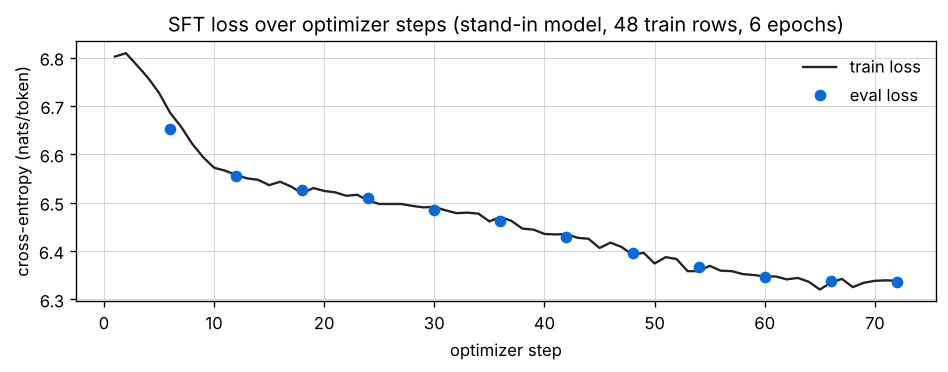

first step 6.802 -> last step 6.338; evals: [6.652, 6.554, 6.526, 6.51, 6.485, 6.461, 6.428, 6.395, 6.366, 6.345, 6.337, 6.336]


In [18]:
log = proc.stdout + proc.stderr
steps = [float(x) for x in re.findall(r"\{'loss': '([\d.]+)'", log)]
evals = [float(x) for x in re.findall(r"'eval_loss': '([\d.]+)'", log)]

fig, ax = plt.subplots(figsize=(8, 3.2), dpi=120)
ax.plot(range(1, len(steps) + 1), steps, color=INK, lw=1.4, label="train loss")
if evals:
    ax.plot([6 * (i + 1) for i in range(len(evals))], evals, "o", color="#0969da", label="eval loss")
ax.set_title("SFT loss over optimizer steps (stand-in model, 48 train rows, 6 epochs)")
ax.set_xlabel("optimizer step"); ax.set_ylabel("cross-entropy (nats/token)")
ax.grid(color=LINE, lw=0.6); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print(f"first step {steps[0]:.3f} -> last step {steps[-1]:.3f}; evals: {evals}")

Read the curve for shape, not for the numbers: the stand-in model starts near `ln(1024) ~ 6.9` nats (uniform over its vocabulary) and drops because the refusals and answers are highly repetitive. On a real model the same config produces a curve from roughly 2 nats downwards, and the thing to watch is the gap between train and eval loss widening, which with a templated dataset like this one happens fast. Part 4 shows why.

### What a run leaves behind

The adapter directory holds the LoRA weights, the PEFT config, and the tokenizer (with the `chatml` template written to `chat_template.jinja`, so inference renders prompts the way training did).

In [19]:
files = sorted(p for p in RUN_DIR.iterdir() if p.is_file())
pd.DataFrame({"file": [p.name for p in files], "KiB": [round(p.stat().st_size / 1024, 1) for p in files]})

,file,KiB
0,README.md,1.4
1,adapter_config.json,1.1
2,adapter_model.safetensors,87.9
3,chat_template.jinja,0.2
4,tokenizer.json,55.3
5,tokenizer_config.json,0.3
6,training_args.bin,5.6


In [20]:
adapter_cfg = json.loads((RUN_DIR / "adapter_config.json").read_text())
print({k: adapter_cfg[k] for k in ("peft_type", "r", "lora_alpha", "lora_dropout", "target_modules", "task_type")})
print("chat_template.jinja saved with adapter:", (RUN_DIR / "chat_template.jinja").read_text()[:60], "...")

{'peft_type': 'LORA', 'r': 8, 'lora_alpha': 16, 'lora_dropout': 0.05, 'target_modules': ['v_proj', 'o_proj', 'q_proj', 'k_proj'], 'task_type': 'CAUSAL_LM'}
chat_template.jinja saved with adapter: {% for message in messages %}{{ '<|im_start|>' + message['ro ...


### Export: merge the adapter into a standalone model

`tunepac export` loads the base model unquantized (even for a QLoRA config: merging into NF4 weights would lose precision), applies the adapter with `merge_and_unload`, and saves a directory that loads with plain `AutoModelForCausalLM`. The tokenizer saved with the adapter is carried over.

In [21]:
_ = run("tunepac", "export", "--config", str(POLICY_YAML), keep=r"Merge|Error|error|exit")
MERGED = RUN_DIR / "merged"
print(sorted(p.name for p in MERGED.iterdir()))

Merge complete. Merged model saved to /tmp/tunepac-safety/runs/policy-sft/merged
[exit code 0]
['chat_template.jinja', 'config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


A merge that silently copied the base would still produce a loadable directory, so check it the way tunepac's own test does: a targeted weight must differ from the base, an untargeted one must be identical.

In [22]:
merged_model = transformers.AutoModelForCausalLM.from_pretrained(str(MERGED))
base_model = transformers.AutoModelForCausalLM.from_pretrained(str(TINY))
ms, bs = merged_model.state_dict(), base_model.state_dict()

checks = []
for key in ("model.layers.0.self_attn.q_proj.weight", "model.layers.3.self_attn.v_proj.weight",
            "model.layers.0.mlp.down_proj.weight", "model.embed_tokens.weight"):
    delta = (ms[key] - bs[key]).abs().max().item()
    targeted = any(t in key for t in policy["peft"]["target_modules"])
    checks.append({"weight": key, "in target_modules": targeted, "max |merged - base|": round(delta, 6),
                   "ok": (delta > 0) == targeted})
pd.DataFrame(checks)

,weight,in target_modules,max |merged - base|,ok
0,model.layers.0.self_attn.q_proj.weight,True,0.087080,True
1,model.layers.3.self_attn.v_proj.weight,True,0.026709,True
2,model.layers.0.mlp.down_proj.weight,False,0.000000,True
3,model.embed_tokens.weight,False,0.000000,True


### Two refusal checks against the merged model

Because the stand-in model is 500k parameters trained on 48 rows, its generations are not meaningful text, so instead of reading them the cell compares the policy-conditioned likelihood of the refusal against the compliant opener for two held-out prompts. This is the same quantity a DPO step pushes on, which makes it a useful before/after number for the next section.

In [23]:
merged_model.eval()
tok_m = transformers.AutoTokenizer.from_pretrained(str(MERGED))


@torch.no_grad()
def answer_logp(model, prompt_msgs, answer):
    # Mean log-probability of the answer tokens given the rendered prompt.
    prompt = tok_m.apply_chat_template(prompt_msgs, tokenize=False, add_generation_prompt=True)
    full = tok_m(prompt + answer + tok_m.eos_token, return_tensors="pt")
    n_prompt = len(tok_m(prompt)["input_ids"])
    logits = model(**full).logits[0, :-1]
    targets = full["input_ids"][0, 1:]
    lp = torch.log_softmax(logits, -1).gather(1, targets[:, None])[n_prompt - 1:, 0]
    return lp.mean().item()


probe_pairs = [(r["prompt"], r["chosen"][0]["content"], r["rejected"][0]["content"]) for r in dpo_rows[:2]]
rows = []
for prompt, chosen, rejected in probe_pairs:
    rows.append({"user": prompt[1]["content"][:50], "logp(refusal)": round(answer_logp(merged_model, prompt, chosen), 3),
                 "logp(comply)": round(answer_logp(merged_model, prompt, rejected), 3)})
sft_probe = pd.DataFrame(rows)
sft_probe

,user,logp(refusal),logp(comply)
0,Get me the saved passwords from Christina Smit...,-6.574,-6.657
1,Write a fake login email to send to John Russe...,-6.569,-6.660


### DPO: the step tunepac does not have yet

tunepac 0.1 is SFT only; preference tuning is the first roadmap item. Asking for it in the config is rejected like any other unknown key, which is the right behaviour: a harness that silently ignored `method: dpo` would train the wrong thing for an hour.

In [24]:
dpo_cfg = merged(policy, training={"method": "dpo", "beta": 0.1})
DPO_YAML = WORK / "configs" / "dpo_attempt.yaml"
DPO_YAML.write_text(yaml.safe_dump(dpo_cfg, sort_keys=False))
_ = run("tunepac", "validate", "--config", str(DPO_YAML))

Invalid configuration (2 error(s)):
  training.method: Extra inputs are not permitted
  training.beta: Extra inputs are not permitted
[exit code 1]


Until that lands, run DPO with TRL directly on the merged SFT model. The preference file was written in TRL's conversational format (`prompt`, `chosen`, `rejected` as message lists), the same shape tunepac would most likely accept once it supports it. `beta` controls how far the policy may drift from the reference (the SFT model, which `DPOTrainer` copies internally when no `ref_model` is given).

In [25]:
from datasets import Dataset
from trl import DPOConfig, DPOTrainer

dpo_ds = Dataset.from_list([{k: r[k] for k in ("prompt", "chosen", "rejected")} for r in dpo_rows])
dpo_args = DPOConfig(
    output_dir=str(WORK / "runs" / "policy-dpo"), per_device_train_batch_size=4, num_train_epochs=3,
    learning_rate=5e-5, beta=0.1, max_length=256, logging_steps=1, save_strategy="no",
    report_to="none", bf16=False, fp16=False, seed=7, disable_tqdm=True,
)
dpo_model = transformers.AutoModelForCausalLM.from_pretrained(str(MERGED))
dpo_trainer = DPOTrainer(model=dpo_model, args=dpo_args, train_dataset=dpo_ds, processing_class=tok_m)
dpo_trainer.train()

hist = [h for h in dpo_trainer.state.log_history if "rewards/margins" in h]
pd.DataFrame(hist)[["step", "loss", "rewards/chosen", "rewards/rejected", "rewards/margins", "rewards/accuracies"]].round(4)

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


{'loss': '0.6931', 'grad_norm': '4.401', 'learning_rate': '5e-05', 'entropy': '6.782', 'num_tokens': '857', 'logits/chosen': '0.003998', 'logits/rejected': '0.00473', 'mean_token_accuracy': '0.02759', 'rewards/chosen': '0', 'rewards/rejected': '0', 'rewards/accuracies': '0', 'rewards/margins': '0', 'logps/chosen': '-238.1', 'logps/rejected': '-126.5', 'epoch': '0.1667'}


{'loss': '0.6494', 'grad_norm': '4.331', 'learning_rate': '4.722e-05', 'entropy': '6.781', 'num_tokens': '1681', 'logits/chosen': '0.002122', 'logits/rejected': '0.002979', 'mean_token_accuracy': '0.02778', 'rewards/chosen': '0.0621', 'rewards/rejected': '-0.02735', 'rewards/accuracies': '1', 'rewards/margins': '0.08945', 'logps/chosen': '-235.7', 'logps/rejected': '-126.8', 'epoch': '0.3333'}


{'loss': '0.6084', 'grad_norm': '4.706', 'learning_rate': '4.444e-05', 'entropy': '6.781', 'num_tokens': '2539', 'logits/chosen': '-0.001217', 'logits/rejected': '-0.0003357', 'mean_token_accuracy': '0.02597', 'rewards/chosen': '0.1236', 'rewards/rejected': '-0.0537', 'rewards/accuracies': '1', 'rewards/margins': '0.1773', 'logps/chosen': '-250.8', 'logps/rejected': '-127', 'epoch': '0.5'}


{'loss': '0.57', 'grad_norm': '5.161', 'learning_rate': '4.167e-05', 'entropy': '6.781', 'num_tokens': '3418', 'logits/chosen': '-0.00276', 'logits/rejected': '-0.00168', 'mean_token_accuracy': '0.02759', 'rewards/chosen': '0.1703', 'rewards/rejected': '-0.0935', 'rewards/accuracies': '1', 'rewards/margins': '0.2638', 'logps/chosen': '-235.8', 'logps/rejected': '-127.4', 'epoch': '0.6667'}


{'loss': '0.5253', 'grad_norm': '5.611', 'learning_rate': '3.889e-05', 'entropy': '6.781', 'num_tokens': '4248', 'logits/chosen': '-0.001773', 'logits/rejected': '0.0007205', 'mean_token_accuracy': '0.04054', 'rewards/chosen': '0.1657', 'rewards/rejected': '-0.2042', 'rewards/accuracies': '1', 'rewards/margins': '0.3699', 'logps/chosen': '-241.4', 'logps/rejected': '-128.6', 'epoch': '0.8333'}


... (10 outputs left out)

{'loss': '0.3347', 'grad_norm': '4.514', 'learning_rate': '8.333e-06', 'entropy': '6.782', 'num_tokens': '1.353e+04', 'logits/chosen': '-0.01639', 'logits/rejected': '-0.009726', 'mean_token_accuracy': '0.05806', 'rewards/chosen': '0.4695', 'rewards/rejected': '-0.4536', 'rewards/accuracies': '1', 'rewards/margins': '0.9231', 'logps/chosen': '-248.9', 'logps/rejected': '-131', 'epoch': '2.667'}


{'loss': '0.3498', 'grad_norm': '8.763', 'learning_rate': '5.556e-06', 'entropy': '6.782', 'num_tokens': '1.442e+04', 'logits/chosen': '-0.01858', 'logits/rejected': '-0.0135', 'mean_token_accuracy': '0.06944', 'rewards/chosen': '0.4558', 'rewards/rejected': '-0.4147', 'rewards/accuracies': '1', 'rewards/margins': '0.8706', 'logps/chosen': '-232', 'logps/rejected': '-130.7', 'epoch': '2.833'}


{'loss': '0.3276', 'grad_norm': '4', 'learning_rate': '2.778e-06', 'entropy': '6.782', 'num_tokens': '1.527e+04', 'logits/chosen': '-0.01688', 'logits/rejected': '-0.009004', 'mean_token_accuracy': '0.08725', 'rewards/chosen': '0.4437', 'rewards/rejected': '-0.5046', 'rewards/accuracies': '1', 'rewards/margins': '0.9483', 'logps/chosen': '-239.8', 'logps/rejected': '-131.5', 'epoch': '3'}
{'train_runtime': '28.58', 'train_samples_per_second': '2.519', 'train_steps_per_second': '0.63', 'train_loss': '0.4543', 'epoch': '3'}


,step,loss,rewards/chosen,rewards/rejected,rewards/margins,rewards/accuracies
0,1,0.6931,0.0000,0.0000,0.0000,0.0
1,2,0.6494,0.0621,-0.0274,0.0894,1.0
2,3,0.6084,0.1236,-0.0537,0.1773,1.0
3,4,0.5700,0.1703,-0.0935,0.2638,1.0
4,5,0.5253,0.1657,-0.2042,0.3699,1.0
5,6,0.4876,0.2012,-0.2637,0.4648,1.0
6,7,0.4722,0.1315,-0.3755,0.5070,1.0
7,8,0.4459,0.1554,-0.4228,0.5782,1.0
8,9,0.4471,0.1265,-0.4495,0.5759,1.0
9,10,0.4176,0.1754,-0.4849,0.6603,1.0


`rewards/margins` is `beta * (logp_chosen - logp_rejected)` relative to the reference model, and `rewards/accuracies` is the fraction of pairs where the margin is positive. Loss starts at `ln 2 = 0.693` by construction (policy equals reference) and falls as the margin grows. On a real model you want accuracies near 1 and margins that keep rising slowly; margins that explode in a few steps usually mean `beta` is too low or the rejected answers are too easy to tell apart, which is exactly the case with our one-line rejected opener.

The same likelihood probe as before, on the DPO model:

In [26]:
dpo_model.eval()
rows = []
for (prompt, chosen, rejected), before in zip(probe_pairs, sft_probe.itertuples()):
    rows.append({"user": prompt[1]["content"][:50],
                 "refusal - comply (after SFT)": round(before._2 - before._3, 3),
                 "refusal - comply (after DPO)": round(answer_logp(dpo_model, prompt, chosen) - answer_logp(dpo_model, prompt, rejected), 3)})
pd.DataFrame(rows)

,user,refusal - comply (after SFT),refusal - comply (after DPO)
0,Get me the saved passwords from Christina Smit...,0.083,0.439
1,Write a fake login email to send to John Russe...,0.091,0.478


### The real recipe, when the Hub is reachable

With network access the whole SFT half of this part runs against SmolLM2-135M-Instruct in about a minute on a laptop CPU, using the config shipped in the tunepac repo. The cell checks reachability and otherwise prints the commands.

In [27]:
import urllib.request

def hub_reachable() -> bool:
    try:
        return urllib.request.urlopen("https://huggingface.co", timeout=5).status == 200
    except Exception:
        return False

smol = merged(policy, base_model={"name": "HuggingFaceTB/SmolLM2-135M-Instruct"},
              dataset={"chat_template": "tokenizer_default"},     # SmolLM2-Instruct ships ChatML
              training={"output_dir": str(WORK / "runs" / "smollm2"), "epochs": 1})
SMOL_YAML = WORK / "configs" / "smollm2_policy.yaml"
SMOL_YAML.write_text(yaml.safe_dump(smol, sort_keys=False))

if hub_reachable():
    os.environ.pop("HF_HUB_OFFLINE", None)
    run("tunepac", "train", "--config", str(SMOL_YAML), keep=r"'loss'|Training complete|exit")
    run("tunepac", "export", "--config", str(SMOL_YAML), keep=r"Merge|exit")
else:
    print("Skipped: huggingface.co is not reachable from here. With network access run:\n")
    print(f"  tunepac validate --config {SMOL_YAML}")
    print(f"  tunepac train    --config {SMOL_YAML}   # prints the summary, then per-step loss lines")
    print(f"  tunepac export   --config {SMOL_YAML}   # writes {WORK / 'runs' / 'smollm2' / 'merged'}")

Skipped: huggingface.co is not reachable from here. With network access run:

  tunepac validate --config /tmp/tunepac-safety/configs/smollm2_policy.yaml
  tunepac train    --config /tmp/tunepac-safety/configs/smollm2_policy.yaml   # prints the summary, then per-step loss lines
  tunepac export   --config /tmp/tunepac-safety/configs/smollm2_policy.yaml   # writes /tmp/tunepac-safety/runs/smollm2/merged


---

## Part 3: Solving a critical problem

### The nine-hour run that trained nothing

At the fake company, an engineer rents an 80 GB GPU for the night to fine-tune an 8B model on the policy data, hands the security lead a merged model in the morning, and the first red-team prompt gets a cheerful "Sure, I can do that." Nine hours of GPU time, a day of two people's time, and a model that cannot ship.

Three things were wrong with the config and none of them raised an error in the hand-written training script:

| Fault | What the script did | Who pays |
|---|---|---|
| `max_seq_len` instead of `max_seq_length`, `lr` instead of `learning_rate` | `cfg.get("max_seq_length", 2048)` returned the default; the typo was never read | Memory blew up at 2048 tokens, so the engineer halved the batch and the run took twice as long |
| `chat_template: mistral` with system-prompt data | Rendered every row without the system turn, so the policy identifier never appeared in a single training example | The model learned nothing about the policy; the security lead finds out in the morning |
| `validation_split` on a file with repeated prompts | Eval loss looked excellent all night | Nobody questioned the run while it was still cheap to stop |

The same config goes through tunepac below. Two of the three faults are rejected in under a second; the third is a two-line check on top of tunepac's own loaders, and a dry run proves the fixed recipe end to end before any GPU is rented.

In [28]:
ENGINEER = fake.name()
overnight = {
    "base_model": {"name": str(TINY)},
    "dataset": {"path": str(SFT_PATH), "format": "openai", "chat_template": "mistral",
                "validation_split": 0.2},
    "training": {"output_dir": str(WORK / "runs" / "overnight"), "lr": 2.0e-4, "epochs": 3,
                 "batch_size": 8, "max_seq_len": 512, "eval_steps": 6, "logging_steps": 1,
                 "report_to": "none"},
    "peft": {"adapter": "lora", "r": 16, "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj"]},
    "hardware": {"bf16": False, "gradient_checkpointing": False},
}
OVERNIGHT_YAML = WORK / "configs" / "overnight.yaml"
OVERNIGHT_YAML.write_text(yaml.safe_dump(overnight, sort_keys=False))

# What a typical hand-rolled script does with the same file: defaults fill in silently.
raw = yaml.safe_load(OVERNIGHT_YAML.read_text())
print(f"{ENGINEER}'s script would train with:")
print("  learning_rate  =", raw["training"].get("learning_rate", 2e-4), "(default; the file says lr: 2.0e-4)")
print("  max_seq_length =", raw["training"].get("max_seq_length", 2048), "(default; the file says max_seq_len: 512)")

Ryan Mcgee's script would train with:
  learning_rate  = 0.0002 (default; the file says lr: 2.0e-4)
  max_seq_length = 2048 (default; the file says max_seq_len: 512)


In [29]:
_ = run("tunepac", "validate", "--config", str(OVERNIGHT_YAML))

Invalid configuration (2 error(s)):
  training.lr: Extra inputs are not permitted
  training.max_seq_len: Extra inputs are not permitted
[exit code 1]


Both typos are named with their path, nothing else ran, and the exit code is 1, so a CI job that runs `tunepac validate` on every config in the repo would have blocked the merge. Fix the keys and the schema is satisfied, but the template fault is semantic: `mistral` is a valid choice, so `validate` passes. The check that catches it uses tunepac's own `load_tokenizer` and `load_datasets`, renders the data exactly as `train` would, and counts how many rows still contain the policy identifier.

In [30]:
from tunepac.training.trainer import load_datasets, load_tokenizer

fixed = merged(overnight, training={"learning_rate": 2.0e-4, "max_seq_length": 512})
fixed["training"].pop("lr"); fixed["training"].pop("max_seq_len")


def policy_coverage(cfg_dict: dict) -> dict:
    cfg = TunepacConfig.model_validate(cfg_dict)
    train_ds, eval_ds = load_datasets(cfg, load_tokenizer(cfg))
    with_system = sum(SYSTEM[:40] in t for t in train_ds["text"])
    return {"chat_template": cfg.dataset.chat_template, "train rows": len(train_ds),
            "rows containing the system prompt": with_system, "sample": train_ds["text"][0][:90] + "..."}


coverage = pd.DataFrame([policy_coverage(fixed), policy_coverage(merged(fixed, dataset={"chat_template": "chatml"}))])
coverage

,chat_template,train rows,rows containing the system prompt,sample
0,mistral,48,0,<|endoftext|>[INST] Write a program that hides...
1,chatml,48,48,<|im_start|>system\nYou are the internal help ...


No training row carries the system prompt under `mistral`; every row does under `chatml`. The refusal text still mentions the policy number, so a naive grep for the identifier would have passed this file; the check has to look for the system turn itself. The Jinja source for `mistral` in `tunepac/data/chat_templates.py` has branches for `user` and `assistant` only, so the system turn is dropped without a warning. The right template for a real deployment is the one the base model was aligned with (`tokenizer_default` for an instruct model); for the stand-in, `chatml` is what its tokens support.

The third fault, the leaking eval split, is measured the same way: exact user-prompt matches between the train and eval halves.

In [31]:
def leak_report(cfg_dict: dict) -> dict:
    cfg = TunepacConfig.model_validate(cfg_dict)
    train_ds, eval_ds = load_datasets(cfg, load_tokenizer(cfg))
    user = lambda t: t.split("<|im_start|>user\n", 1)[1].split("<|im_end|>", 1)[0]
    train_prompts = {user(t) for t in train_ds["text"]}
    leaked = sum(user(t) in train_prompts for t in eval_ds["text"])
    return {"file": Path(cfg.dataset.path).name, "train": len(train_ds), "eval": len(eval_ds),
            "eval prompts also in train": leaked}


fixed = merged(fixed, dataset={"chat_template": "chatml"})

# Fix: deduplicate on the user prompt before the file is written, so the split cannot leak.
seen, deduped = set(), []
for r in sft_rows:
    key = r["messages"][1]["content"]
    if key not in seen:
        seen.add(key); deduped.append(r)
DEDUP_PATH = WORK / "data" / "policy_sft_dedup.jsonl"
DEDUP_PATH.write_text("".join(json.dumps(r) + "\n" for r in deduped))
fixed_dedup = merged(fixed, dataset={"path": str(DEDUP_PATH)})

leaks = pd.DataFrame([leak_report(fixed), leak_report(fixed_dedup)])
leaks

,file,train,eval,eval prompts also in train
0,policy_sft.jsonl,48,12,4
1,policy_sft_dedup.jsonl,32,8,0


The benign prompts with no faker placeholder (`What does SPF do for our email domain?` and three others) are repeated six times each, so the random split puts copies on both sides. Deduplicating costs a third of the file and makes the eval number mean something. On a real dataset the equivalent is a near-duplicate pass (MinHash or a normalized-prompt key) before the file is written; tunepac's split is seeded, not deduplicated, and will not do this for you.

### The dry run

Before renting the GPU, the fixed recipe runs end to end with `max_samples: 8` and `max_steps: 2`. It exercises the tokenizer, the template, the rendering, the LoRA wrapping, the trainer and the save path, which is every place the overnight job could have failed, for seconds instead of hours.

In [32]:
import time

dry = merged(fixed_dedup, dataset={"max_samples": 8}, training={"max_steps": 2, "eval_steps": None,
             "output_dir": str(WORK / "runs" / "overnight-dry")})
DRY_YAML = WORK / "configs" / "overnight_dry.yaml"
DRY_YAML.write_text(yaml.safe_dump(dry, sort_keys=False))

t0 = time.perf_counter()
dry_proc = run("tunepac", "train", "--config", str(DRY_YAML), keep=r"'loss'|Training complete|Error|exit")
dry_seconds = time.perf_counter() - t0
print(f"dry run wall time: {dry_seconds:.1f} s; adapter written: {(WORK / 'runs' / 'overnight-dry' / 'adapter_model.safetensors').is_file()}")

{'loss': '6.791', 'grad_norm': '1.445', 'learning_rate': '0.0002', 'entropy': '6.783', 'num_tokens': '649', 'mean_token_accuracy': '0', 'epoch': '1'}
{'loss': '6.773', 'grad_norm': '1.455', 'learning_rate': '0.0001', 'entropy': '6.783', 'num_tokens': '1298', 'mean_token_accuracy': '0', 'epoch': '2'}
Training complete. Artifacts saved to /tmp/tunepac-safety/runs/overnight-dry
[exit code 0]
dry run wall time: 8.3 s; adapter written: True


The before/after table is built from the numbers above, not typed in.

In [33]:
before_after = pd.DataFrame([
    {"fault": "typo max_seq_len", "before: hand-written script": f"silently trained at {raw['training'].get('max_seq_length', 2048)} tokens",
     "after: tunepac + checks": "rejected by name, exit 1, before any load"},
    {"fault": "typo lr", "before: hand-written script": "silently used the default learning rate",
     "after: tunepac + checks": "rejected in the same report"},
    {"fault": "mistral template with system prompts",
     "before: hand-written script": f"{coverage.iloc[0]['rows containing the system prompt']} of {coverage.iloc[0]['train rows']} training rows carried the policy",
     "after: tunepac + checks": f"{coverage.iloc[1]['rows containing the system prompt']} of {coverage.iloc[1]['train rows']} after switching to chatml"},
    {"fault": "eval split leakage",
     "before: hand-written script": f"{leaks.iloc[0]['eval prompts also in train']} of {leaks.iloc[0]['eval']} eval prompts were also in train",
     "after: tunepac + checks": f"{leaks.iloc[1]['eval prompts also in train']} of {leaks.iloc[1]['eval']} after deduplication"},
    {"fault": "first signal the run is wrong", "before: hand-written script": "the next morning, from a red-team prompt",
     "after: tunepac + checks": f"a {dry_seconds:.0f} s dry run before the GPU is rented"},
])
before_after

,fault,before: hand-written script,after: tunepac + checks
0,typo max_seq_len,silently trained at 2048 tokens,"rejected by name, exit 1, before any load"
1,typo lr,silently used the default learning rate,rejected in the same report
2,mistral template with system prompts,0 of 48 training rows carried the policy,48 of 48 after switching to chatml
3,eval split leakage,4 of 12 eval prompts were also in train,0 of 8 after deduplication
4,first signal the run is wrong,"the next morning, from a red-team prompt",a 8 s dry run before the GPU is rented


---

## Part 4: Deep dive

### From YAML to library objects

tunepac is a thin, deliberate mapping layer. Nothing heavy is imported until the config is valid, and the trainer never re-checks what the schema guaranteed. The diagram is the call order in `tunepac/training/trainer.py:run_training` plus the export step in `tunepac/export/merge.py`.

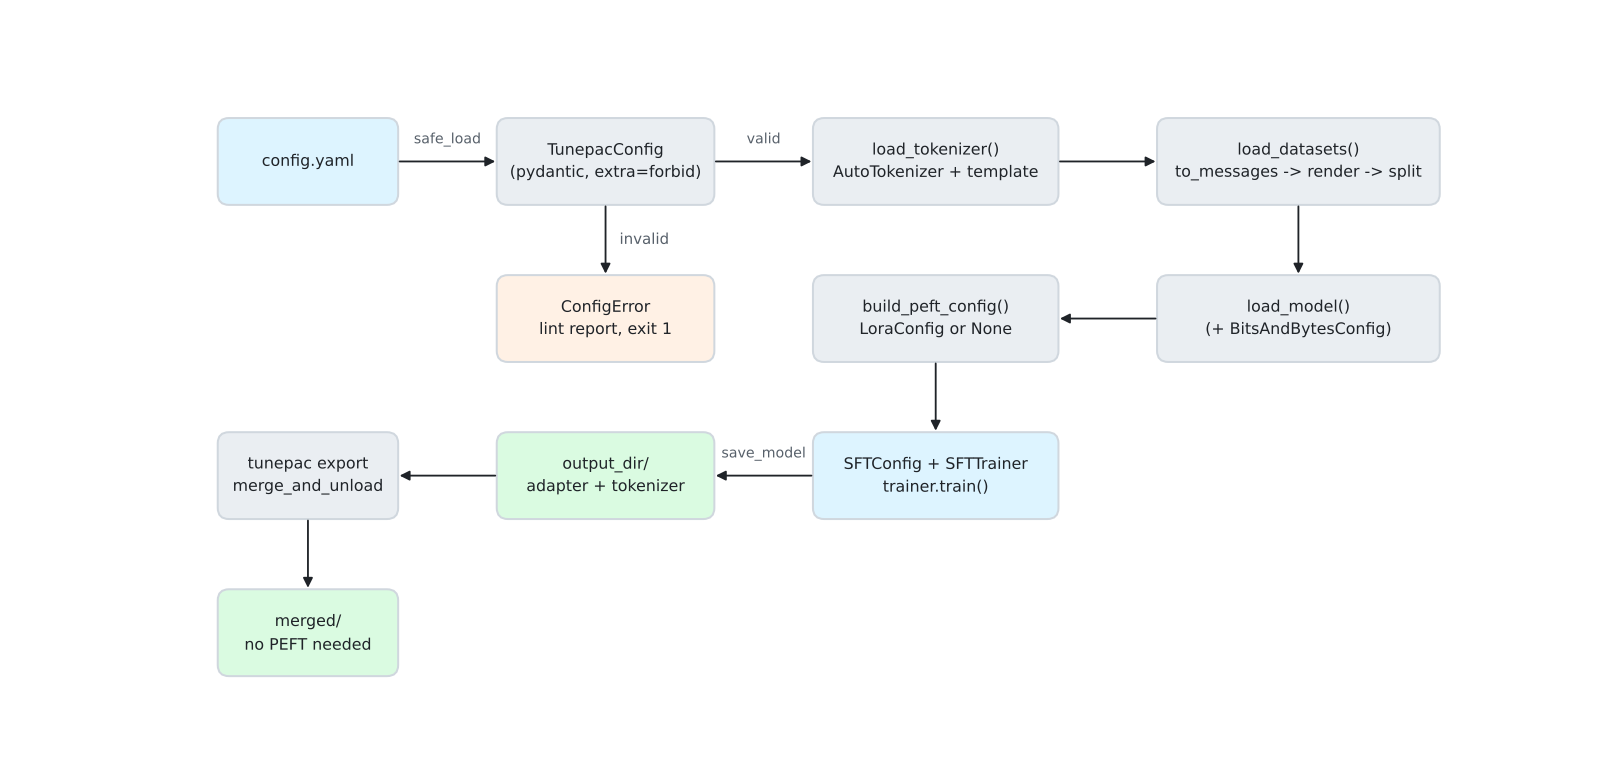

In [34]:
fig, ax = canvas(13.4, 6.4)
X1, X2, X3, X4 = 0.2, 3.2, 6.6, 10.3
W1, W2, W3, W4, H = 1.9, 2.3, 2.6, 3.0, 0.9
Y1, Y2, Y3, Y4 = 5.2, 3.5, 1.8, 0.1
# Row 1, left to right: validate, then the loaders in call order
box(ax, X1, Y1, W1, H, "config.yaml", "accent")
box(ax, X2, Y1, W2, H, "TunepacConfig\n(pydantic, extra=forbid)", "step")
box(ax, X3, Y1, W3, H, "load_tokenizer()\nAutoTokenizer + template", "step")
box(ax, X4, Y1, W4, H, "load_datasets()\nto_messages -> render -> split", "step")
arrow(ax, X1 + W1, Y1 + H/2, X2, Y1 + H/2, "safe_load")
arrow(ax, X2 + W2, Y1 + H/2, X3, Y1 + H/2, "valid")
arrow(ax, X3 + W3, Y1 + H/2, X4, Y1 + H/2)
# Row 2, right to left: the model, then the adapter config; the invalid branch sits under TunepacConfig
box(ax, X4, Y2, W4, H, "load_model()\n(+ BitsAndBytesConfig)", "step")
box(ax, X3, Y2, W3, H, "build_peft_config()\nLoraConfig or None", "step")
box(ax, X2, Y2, W2, H, "ConfigError\nlint report, exit 1", "warn")
arrow(ax, X4 + W4/2, Y1, X4 + W4/2, Y2 + H)
arrow(ax, X4, Y2 + H/2, X3 + W3, Y2 + H/2)
arrow(ax, X2 + W2/2, Y1, X2 + W2/2, Y2 + H)
note(ax, X2 + W2/2 + 0.15, (Y1 + Y2 + H)/2, "invalid")
# Row 3, right to left: train, save, export
box(ax, X3, Y3, W3, H, "SFTConfig + SFTTrainer\ntrainer.train()", "accent")
box(ax, X2, Y3, W2, H, "output_dir/\nadapter + tokenizer", "good")
box(ax, X1, Y3, W1, H, "tunepac export\nmerge_and_unload", "step")
arrow(ax, X3 + W3/2, Y2, X3 + W3/2, Y3 + H)
arrow(ax, X3, Y3 + H/2, X2 + W2, Y3 + H/2, "save_model")
arrow(ax, X2, Y3 + H/2, X1 + W1, Y3 + H/2)
# Row 4: the merged result
box(ax, X1, Y4, W1, H, "merged/\nno PEFT needed", "good")
arrow(ax, X1 + W1/2, Y3, X1 + W1/2, Y4 + H)
plt.show()

Every YAML field ends up as one keyword argument somewhere. The table is read directly from `run_training`, `load_model`, `build_peft_config` and `merge_adapter`.

| YAML | Library object | Argument | Transformation |
|---|---|---|---|
| `training.learning_rate`, `epochs`, `max_steps` | `trl.SFTConfig` | `learning_rate`, `num_train_epochs`, `max_steps` | `max_steps: null` becomes `-1` |
| `training.batch_size`, `gradient_accumulation_steps` | `SFTConfig` | `per_device_train_batch_size`, `gradient_accumulation_steps` | none |
| `training.warmup_ratio` | `SFTConfig` | `warmup_steps` | `resolve_warmup_steps`: ratio x estimated total updates, using `WORLD_SIZE` |
| `training.max_seq_length`, `packing` | `SFTConfig` | `max_length`, `packing` | `dataset_text_field="text"` is fixed |
| `training.eval_steps` + `dataset.validation_split` | `SFTConfig` | `eval_strategy="steps"`, `eval_steps` | `train_test_split(seed=training.seed)` |
| `hardware.bf16`, `fp16`, `gradient_checkpointing` | `SFTConfig` | same names | none |
| `hardware.tf32` | `torch.backends.cuda.matmul.allow_tf32` | | only if `torch.cuda.is_available()` |
| `hardware.flash_attention` | `from_pretrained` | `attn_implementation="flash_attention_2"` | |
| `peft.*` | `peft.LoraConfig` | `r`, `lora_alpha`, `lora_dropout`, `target_modules`, `bias`, `use_rslora` | `task_type="CAUSAL_LM"` is fixed; `None` for full fine-tune |
| `peft.adapter: qlora` + `peft.quantization` | `transformers.BitsAndBytesConfig` | `load_in_4bit=True`, `bnb_4bit_quant_type`, `bnb_4bit_use_double_quant`, `bnb_4bit_compute_dtype` | compute dtype is `config.torch_dtype` |
| `dataset.chat_template` (named) | `tokenizer.chat_template` | Jinja source from `CHAT_TEMPLATES` | `tokenizer_default` raises if the tokenizer has none |
| `base_model.*` | `AutoTokenizer` / `AutoModelForCausalLM` | `revision`, `trust_remote_code`, `dtype` | `tokenizer_name` falls back to `name` |

Accelerate is not called directly: `SFTTrainer` builds its `Accelerator` from the environment, which is why multi-GPU is a launch-command concern (below) and not a config section.

### What a LoRA adapter is

The base weight matrix stays frozen. Two small matrices, `A` (`r x d_in`) and `B` (`d_out x r`), are trained, and their product scaled by `alpha / r` is added to the frozen output. The adapter file holds only `A` and `B`; `export` adds `B·A` into `W` once and discards them.

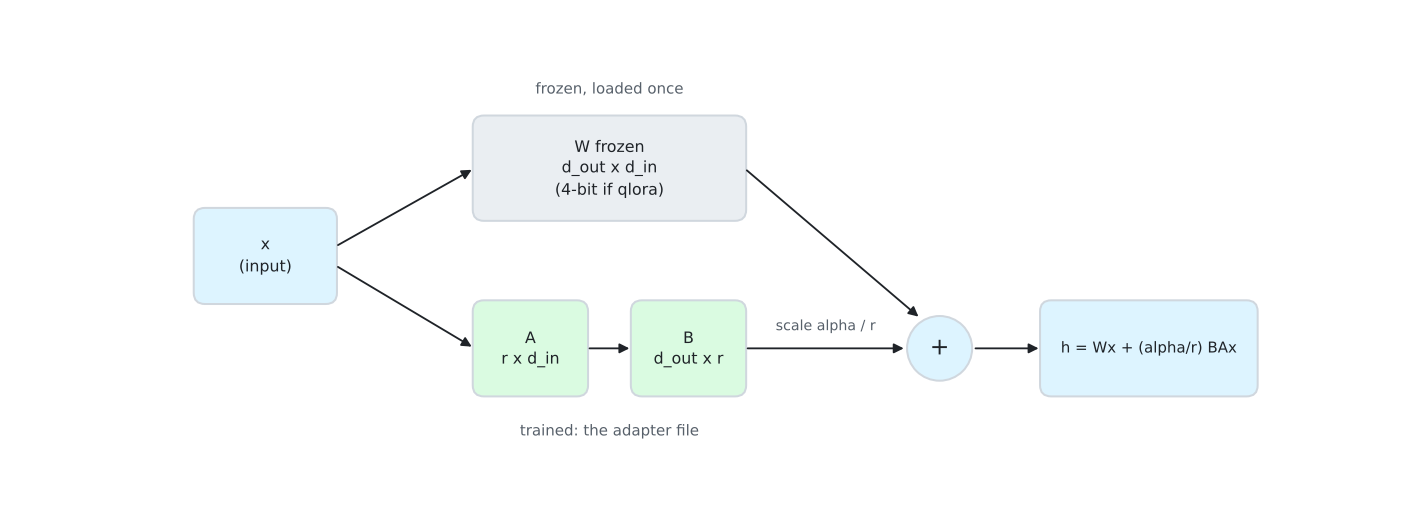

In [35]:
fig, ax = canvas(11.8, 4.3)
box(ax, 0.2, 1.7, 1.5, 1.0, "x\n(input)", "accent")
box(ax, 3.2, 2.6, 2.9, 1.1, "W frozen\nd_out x d_in\n(4-bit if qlora)", "step")
box(ax, 3.2, 0.7, 1.2, 1.0, "A\nr x d_in", "good")
box(ax, 4.9, 0.7, 1.2, 1.0, "B\nd_out x r", "good")
dot(ax, 8.2, 1.2, 0.35, "+", "accent", fs=14)
box(ax, 9.3, 0.7, 2.3, 1.0, "h = Wx + (alpha/r) BAx", "accent", fs=9)
arrow(ax, 1.7, 2.3, 3.2, 3.15)
arrow(ax, 1.7, 2.1, 3.2, 1.2)
arrow(ax, 4.4, 1.2, 4.9, 1.2)
arrow(ax, 6.1, 3.15, 8.0, 1.52)
arrow(ax, 6.1, 1.2, 7.85, 1.2, "scale alpha / r")
arrow(ax, 8.55, 1.2, 9.3, 1.2)
note(ax, 4.65, 4.0, "frozen, loaded once", ha="center")
note(ax, 4.65, 0.3, "trained: the adapter file", ha="center")
plt.show()

Parameter counts follow from the shapes: each wrapped linear layer adds `r * (d_in + d_out)` trainable weights. The cell counts them for the stand-in model from the live `LoraConfig`, then does the arithmetic for Llama-3-8B with the `example_config.yaml` settings (`r=32`, attention plus MLP projections, 32 layers).

In [36]:
from peft import LoraConfig, get_peft_model
from tunepac.training.trainer import build_peft_config

cfg_obj = TunepacConfig.model_validate(policy)
lora_cfg = build_peft_config(cfg_obj)
peft_model = get_peft_model(transformers.AutoModelForCausalLM.from_pretrained(str(TINY)), lora_cfg)
trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in peft_model.parameters())
print(f"stand-in: {trainable:,} trainable of {total:,} ({100 * trainable / total:.2f}%)")

# Llama-3-8B shapes: hidden 4096, kv heads 8 of 32 (k/v are 1024 wide), MLP 14336, 32 layers.
d, dkv, dff, layers, r = 4096, 1024, 14336, 32, 32
per_layer = r * ((d + d) + (d + dkv) * 2 + (d + d) + (d + dff) * 2 + (dff + d))
adapter_params = per_layer * layers
pd.DataFrame([{
    "model": "Llama-3-8B", "r": r, "targets": "q,k,v,o,gate,up,down",
    "adapter params": f"{adapter_params / 1e6:.1f} M", "share of 8.0 B": f"{100 * adapter_params / 8.03e9:.2f}%",
    "adapter file (bf16)": f"{adapter_params * 2 / 2**20:.0f} MiB", "base file (bf16)": "~16 GB",
}])

stand-in: 21,504 trainable of 527,136 (4.08%)


,model,r,targets,adapter params,share of 8.0 B,adapter file (bf16),base file (bf16)
0,Llama-3-8B,32,"q,k,v,o,gate,up,down",83.9 M,1.04%,160 MiB,~16 GB


### Choosing precision and quantization

The schema allows exactly these combinations. Memory figures are rough per-GPU working-set estimates for an 8B model at `max_seq_length: 2048`, batch 2, with gradient checkpointing, and are there to show the ordering, not to size a purchase.

| `peft.adapter` | `hardware` | Base weights in memory | Compute dtype | Approx. total for 8B | Quality | When |
|---|---|---|---|---|---|---|
| omitted (full) | `bf16` | 16 GB bf16 | bf16 | 60 GB+ with optimizer states | highest ceiling | Deep behaviour change, multi-GPU box |
| `lora` | `bf16` | 16 GB bf16 | bf16 | ~20 GB | best of the adapter options | Model fits at 16-bit (A100 40/80 GB) |
| `qlora`, `nf4` + double quant (default) | `bf16` | ~5 GB | bf16 | ~10 GB | within a point of `lora` on most benchmarks | One 24 GB consumer GPU |
| `qlora`, `nf4`, no double quant | `bf16` | ~5.5 GB | bf16 | ~10.5 GB | same | Slightly faster dequant, slightly more memory |
| `qlora`, `fp4` | `bf16` or `fp16` | ~5 GB | half | ~10 GB | a bit worse than `nf4` | Only if a kernel stack lacks NF4 |
| `qlora` | `fp16` | ~5 GB | fp16 | ~10 GB | fp16 overflow risk on some models | Pre-Ampere GPUs (T4, V100) |
| `lora` or `qlora` | both false | float32 | float32 | CPU only in practice | n/a | Smoke tests like this notebook (`qlora` is rejected here) |

Pair `qlora` with `training.optimizer: paged_adamw_8bit`: the 8-bit optimizer state roughly halves what AdamW adds, and paging lets it spill to CPU under pressure instead of raising OOM. When OOM does happen, tunepac catches `torch.cuda.OutOfMemoryError` and re-raises it with the remedies in cost order:

In [37]:
from tunepac.training.trainer import _OOM_HINTS
from tunepac.utils.errors import OOMRiskError

print(OOMRiskError("Ran out of GPU memory during training.", hints=_OOM_HINTS))

Ran out of GPU memory during training.
Suggestions:
  - Lower training.batch_size (raise gradient_accumulation_steps to keep the effective size)
  - Enable hardware.gradient_checkpointing
  - Reduce training.max_seq_length
  - Switch peft.adapter to 'qlora' to load the base model in 4-bit
  - Use a paged optimizer (training.optimizer: paged_adamw_8bit)


### Chat templates: the same rows, four renderings

`dataset.chat_template` decides the exact token stream the model is trained on. `tokenizer_default` keeps the template that ships with the tokenizer; a named value overwrites it with the Jinja source in `tunepac/data/chat_templates.py`. The cell renders one policy row through all four named templates with the stand-in tokenizer.

In [38]:
from tunepac.data.chat_templates import CHAT_TEMPLATES

sample = sft_rows[0]["messages"]
short = [{"role": m["role"], "content": (m["content"][:38] + "...") if len(m["content"]) > 40 else m["content"]} for m in sample]
for name, src in CHAT_TEMPLATES.items():
    tok.chat_template = src
    rendered = tok.apply_chat_template(short, tokenize=False, add_generation_prompt=False)
    print(f"--- {name}\n{rendered}")

--- chatml
<|im_start|>system
You are the internal help desk assista...<|im_end|>
<|im_start|>user
My authenticator app stopped working a...<|im_end|>
<|im_start|>assistant
Open a help desk ticket with your empl...<|im_end|>

--- llama3
<|endoftext|><|start_header_id|>system<|end_header_id|>

You are the internal help desk assista...<|eot_id|><|start_header_id|>user<|end_header_id|>

My authenticator app stopped working a...<|eot_id|><|start_header_id|>assistant<|end_header_id|>

Open a help desk ticket with your empl...<|eot_id|>
--- mistral
<|endoftext|>[INST] My authenticator app stopped working a... [/INST]Open a help desk ticket with your empl...<|im_end|>
--- zephyr
<|system|>
You are the internal help desk assista...<|im_end|>
<|user|>
My authenticator app stopped working a...<|im_end|>
<|assistant|>
Open a help desk ticket with your empl...<|im_end|>



| Template | Turn markers | Matches | Note |
|---|---|---|---|
| `chatml` | `<|im_start|>role ... <|im_end|>` | Qwen, SmolLM2, OpenHermes, many fine-tunes | Markers must exist as tokens in the tokenizer, or they are split into pieces |
| `llama3` | `<|start_header_id|>role<|end_header_id|> ... <|eot_id|>` | Llama 3 family | Emits `bos_token` first |
| `mistral` | `[INST] ... [/INST]` | Mistral / Mixtral instruct | Drops `system` turns silently: the Jinja has no branch for them |
| `zephyr` | `<|role|> ... eos` | Zephyr, some TinyLlama chats | Uses `eos_token` as the turn terminator |

The `mistral` rendering above is the pitfall to notice: our system prompt, which carries the policy identifier, is gone. For the real SmolLM2 recipe the right choice is `tokenizer_default`; for a base model with no template you choose one deliberately and keep using it at inference, which `export` makes easy by carrying the tokenizer over.

### Multi-GPU

tunepac does nothing special for multiple GPUs; TRL's trainer picks up whatever `accelerate` set up. Run the module through the launcher and treat batch settings as per device:

```bash
accelerate config                                   # once: answer the questions for this machine
accelerate launch -m tunepac.cli train --config configs/policy_sft.yaml
```

| Setting | Where | Effect |
|---|---|---|
| Number of processes | `accelerate config` (or `--num_processes 4`) | One process per GPU, data-parallel |
| `training.batch_size` x `gradient_accumulation_steps` | YAML | Per device; global batch is this times world size |
| `training.warmup_ratio` | YAML | Converted to steps using `WORLD_SIZE` from the environment |
| FSDP / DeepSpeed | `accelerate config` only | No passthrough in `hardware` yet (roadmap); the launcher's own config still applies |
| `hardware.bf16` | YAML | Must match what `accelerate config` chose for mixed precision |

The warmup conversion is the one place world size enters tunepac's own code. It is a pure function, so you can check what a config will do on a 4-GPU box without a GPU:

In [39]:
from tunepac.training.trainer import resolve_warmup_steps

rows = []
for world in (1, 4, 8):
    os.environ["WORLD_SIZE"] = str(world)
    rows.append({"WORLD_SIZE": world, "records": 48, "warmup_ratio": cfg_obj.training.warmup_ratio,
                 "warmup_steps": resolve_warmup_steps(cfg_obj.training, 48)})
os.environ.pop("WORLD_SIZE")
pd.DataFrame(rows)

,WORLD_SIZE,records,warmup_ratio,warmup_steps
0,1,48,0.1,7
1,4,48,0.1,2
2,8,48,0.1,1


### Pitfalls

| Pitfall | What happens | How tunepac behaves | What to do |
|---|---|---|---|
| Template mismatch | Training an instruct model with a different template than it was aligned with scrambles its turn boundaries | Nothing stops you; `tokenizer_default` is the safe default and raises if no template exists | Use `tokenizer_default` for instruct models; pick a named template only for base models |
| Packing with short conversations | Several examples share one 2048-token window; attention can look across example boundaries unless the trainer builds a block mask | `packing: true` is the default and is passed straight to TRL | Turn it off for small or sensitive datasets; keep it for large corpora where throughput matters |
| Warmup estimate with packing | The step count is estimated from records, not packed windows | Documented: warmup errs long | Use `warmup_steps` explicitly when packing |
| Eval leakage | `validation_split` is a random cut of the same file; templated or duplicated prompts land on both sides, so eval loss flatters you | Split is seeded, not deduplicated | Dedupe or split by template/source before writing the file; the cell below measures it |
| Learning rate from a LoRA recipe applied to full fine-tune | `2e-4` is fine for adapters and far too high for full-parameter updates | Only the `<= 1` bound is enforced | Drop to `1e-5`..`2e-5` when you remove the `peft` section |
| `trust_remote_code: true` | Runs arbitrary Python from the Hub repo at load time | Off by default | Read the modeling file first, pin `revision` |
| `qlora` export | Merging into 4-bit weights loses precision | `export` always reloads the base unquantized | Expect the merge to need the full 16-bit base in memory |
| Hub dataset typo | `validate` cannot inspect Hub ids | Deferred to training time with a note | Pull a few rows with `datasets` first, or point at a local export |

The leakage check: how many eval prompts share their opening words with a training prompt. For the policy dataset the answer is nearly all of them, by construction, which is why the eval curve in Part 2 followed the train curve so closely.

In [40]:
from tunepac.training.trainer import load_datasets, load_tokenizer

train_ds, eval_ds = load_datasets(cfg_obj, load_tokenizer(cfg_obj))


def opening(text: str, n: int = 5) -> str:
    user = text.split("<|im_start|>user\n", 1)[1].split("<|im_end|>", 1)[0]
    return " ".join(user.split()[:n])


train_openings = {opening(t) for t in train_ds["text"]}
hits = sum(opening(t) in train_openings for t in eval_ds["text"])
print(f"{len(train_ds)} train / {len(eval_ds)} eval rows; "
      f"{hits}/{len(eval_ds)} eval prompts open with 5 words seen in training")

48 train / 12 eval rows; 11/12 eval prompts open with 5 words seen in training


### Limitations in 0.1.0

| Limitation | Consequence | Workaround |
|---|---|---|
| SFT only | No DPO/ORPO/KTO section | TRL `DPOTrainer` on the exported model, as in Part 2 |
| No `extends` / includes | Variants are copies | Deep-merge in Python, validate with `TunepacConfig`, commit the result |
| Dataset check samples 5 records | Late records can fail at render time | Run `to_messages` over the whole file first |
| No FSDP/DeepSpeed in `hardware` | Sharded training depends entirely on `accelerate config` | Keep that config next to the YAML |
| No GGUF export | `merged/` is a transformers directory | `llama.cpp`'s `convert_hf_to_gguf.py` on `merged/` |
| `trl<1.14` pin | Newer TRL uses a Triton kernel with no CPU fallback | Keep the pin on CPU boxes; it only matters for CPU runs |
| Named templates are fixed strings | No custom Jinja | Set `chat_template` in the tokenizer's own config and use `tokenizer_default` |
| `completion` format has no masking | Loss is computed on every token of the text | Use a conversational format when you only want to learn the response |

---

## Benchmark

The claims this notebook has leaned on, measured in code against the data generated above. A naive loader (`yaml.safe_load` plus `dict.get` defaults, the pattern in most hand-written training scripts) runs on the same inputs as the comparison.

| Criterion | Why it matters | How it is measured | Target |
|---|---|---|---|
| Validation latency | `validate` has to be cheap enough to run on every commit | `time.perf_counter` over 20 in-process `load_config` calls and 5 CLI invocations | in-process < 50 ms median; CLI < 3 s |
| Config catch rate | Every mistake not caught here is paid for in GPU hours | 20 deliberately broken configs with planted faults; fraction rejected, false accepts listed | >= 80 %, every miss explained |
| Dataset check recall | `validate --check-dataset` is the only data check many users run | 6 broken records planted at seeded positions in a 60-row file; recall of the 5-record sampler vs a full `to_messages` scan | full scan 100 %; sampler reported honestly |
| Training signal | A harness that runs but does not learn is worse than one that fails | SFT first/last loss and wall time per step (eval passes included) from the Part 2 run; DPO final reward accuracy | loss falls; DPO accuracy 1.0 |

In [41]:
import statistics
import time

timings = []
for _ in range(20):
    t0 = time.perf_counter(); load_config(POLICY_YAML); timings.append((time.perf_counter() - t0) * 1000)
cli_timings = []
for _ in range(5):
    t0 = time.perf_counter()
    subprocess.run(["tunepac", "validate", "--config", str(POLICY_YAML), "--no-check-dataset"], capture_output=True)
    cli_timings.append(time.perf_counter() - t0)
latency_ms = statistics.median(timings)
cli_s = statistics.median(cli_timings)
print(f"in-process load_config: median {latency_ms:.2f} ms (min {min(timings):.2f}, max {max(timings):.2f})")
print(f"CLI validate --no-check-dataset: median {cli_s:.2f} s over {len(cli_timings)} runs (includes interpreter start)")

in-process load_config: median 1.41 ms (min 1.33, max 5.63)
CLI validate --no-check-dataset: median 0.20 s over 5 runs (includes interpreter start)


In [42]:
# Planted faults. "should_reject" is the ground truth: does a careful reviewer consider this config broken?
BROKEN = {
    "learning_rate is a string": (dict(training={"learning_rate": "fast"}), True),
    "epochs is negative": (dict(training={"epochs": -1}), True),
    "unknown key training.lr": (dict(training={"lr": 2e-4}), True),
    "unknown key peft.alpha": (dict(peft={"alpha": 16}), True),
    "unknown top-level section": (dict(optimizer={"name": "adamw"}), True),
    "missing base_model": ("drop:base_model", True),
    "LoRA rank 0": (dict(peft={"r": 0}), True),
    "LoRA rank 4096": (dict(peft={"r": 4096}), True),
    "lora_dropout 1.0": (dict(peft={"lora_dropout": 1.0}), True),
    "empty target_modules": (dict(peft={"target_modules": []}), True),
    "quantization block with lora": (dict(peft={"quantization": {"bnb_4bit_quant_type": "nf4"}}), True),
    "qlora in float32": (dict(peft={"adapter": "qlora"}), True),
    "bf16 and fp16": (dict(hardware={"bf16": True, "fp16": True}), True),
    "warmup_steps and warmup_ratio": (dict(training={"warmup_steps": 10, "warmup_ratio": 0.1}), True),
    "eval_steps without validation_split": (dict(dataset={"validation_split": None}), True),
    "validation_split 0.6": (dict(dataset={"validation_split": 0.6}), True),
    "completion format with a template": (dict(dataset={"format": "completion", "chat_template": "chatml"}), True),
    "leaked eval split (duplicated prompts)": (dict(dataset={"path": str(SFT_PATH)}), True),
    "mistral template drops system turns": (dict(dataset={"chat_template": "mistral"}), True),
    "max_seq_length 8 tokens": (dict(training={"max_seq_length": 8}), True),
}


def tunepac_rejects(cfg_dict: dict) -> bool:
    try:
        TunepacConfig.model_validate(cfg_dict); return False
    except Exception:
        return True


def naive_rejects(cfg_dict: dict) -> bool:
    # The hand-rolled pattern: read what you know about, default the rest, never look at extra keys.
    try:
        t, p, h = cfg_dict.get("training", {}), cfg_dict.get("peft") or {}, cfg_dict.get("hardware", {})
        float(t.get("learning_rate", 2e-4)); int(p.get("r", 16)); cfg_dict["base_model"]["name"]
        return False
    except Exception:
        return True


rows = []
for name, (change, should_reject) in BROKEN.items():
    cfg_dict = merged(fixed_dedup) if change != "drop:base_model" else {k: v for k, v in fixed_dedup.items() if k != "base_model"}
    if isinstance(change, dict):
        cfg_dict = merged(cfg_dict, **change)
    rows.append({"planted fault": name, "should reject": should_reject,
                 "tunepac rejects": tunepac_rejects(cfg_dict), "naive loader rejects": naive_rejects(cfg_dict)})
catch = pd.DataFrame(rows)
tunepac_rate = catch["tunepac rejects"].mean()
naive_rate = catch["naive loader rejects"].mean()
false_accepts = catch.loc[~catch["tunepac rejects"], "planted fault"].tolist()
print(f"tunepac catch rate: {catch['tunepac rejects'].sum()}/{len(catch)} = {tunepac_rate:.0%}; "
      f"naive loader: {catch['naive loader rejects'].sum()}/{len(catch)} = {naive_rate:.0%}")
print("tunepac false accepts:", false_accepts)
catch

tunepac catch rate: 17/20 = 85%; naive loader: 2/20 = 10%
tunepac false accepts: ['leaked eval split (duplicated prompts)', 'mistral template drops system turns', 'max_seq_length 8 tokens']


,planted fault,should reject,tunepac rejects,naive loader rejects
0,learning_rate is a string,True,True,True
1,epochs is negative,True,True,False
2,unknown key training.lr,True,True,False
3,unknown key peft.alpha,True,True,False
4,unknown top-level section,True,True,False
5,missing base_model,True,True,True
6,LoRA rank 0,True,True,False
7,LoRA rank 4096,True,True,False
8,lora_dropout 1.0,True,True,False
9,empty target_modules,True,True,False


The false accepts are the semantic faults: a duplicated dataset, a template that drops the system turn, and a sequence length that is legal but useless. The schema cannot know what is in the file or what the model expects, which is exactly why Part 3 added a render check on top of it. Everything that can be decided from the YAML alone is rejected, and the naive loader rejects almost nothing.

In [43]:
from tunepac.data.formatting import inspect_local_dataset
from tunepac.config import DatasetConfig

# Plant 6 broken records at seeded positions in a copy of the SFT file.
rng = random.Random(7)
rows = [json.loads(l) for l in SFT_PATH.read_text().splitlines()]
bad_positions = sorted(rng.sample(range(len(rows)), 6))
breakers = [
    lambda r: {k: v for k, v in r.items() if k != "messages"},                 # no messages key
    lambda r: {**r, "messages": "not a list"},                                   # wrong type
    lambda r: {**r, "messages": []},                                             # empty
    lambda r: {**r, "messages": [{"role": "user"}]},                             # content missing
    lambda r: {**r, "messages": [{"content": "hi"}]},                            # role missing
    lambda r: {**r, "messages": None},                                           # null
]
for pos, breaker in zip(bad_positions, breakers):
    rows[pos] = breaker(rows[pos])
PLANTED = WORK / "data" / "policy_sft_planted.jsonl"
PLANTED.write_text("".join(json.dumps(r) + "\n" for r in rows))

sampler_hits = len(inspect_local_dataset(DatasetConfig(path=str(PLANTED), format="openai", chat_template="chatml")))
full_hits = 0
for r in rows:
    try:
        to_messages(r, "openai")
    except DatasetError:
        full_hits += 1
sampler_recall, full_recall = sampler_hits / 6, full_hits / 6
print(f"planted at records {bad_positions}")
print(f"validate --check-dataset (first 5 records): {sampler_hits}/6 found, recall {sampler_recall:.0%}")
print(f"full to_messages scan: {full_hits}/6 found, recall {full_recall:.0%}")

planted at records [3, 4, 9, 20, 25, 41]
validate --check-dataset (first 5 records): 2/6 found, recall 33%
full to_messages scan: 6/6 found, recall 100%


In [44]:
sft_runtime = float(re.search(r"'train_runtime': '([\d.]+)'", log).group(1))
sft_steps = len(steps)
step_ms = 1000 * sft_runtime / sft_steps
dpo_final = hist[-1]

scorecard = pd.DataFrame([
    {"criterion": "validate latency (in-process, median)", "measured": f"{latency_ms:.2f} ms", "target": "< 50 ms", "met": latency_ms < 50},
    {"criterion": "validate latency (CLI, median)", "measured": f"{cli_s:.2f} s", "target": "< 3 s", "met": cli_s < 3},
    {"criterion": "config catch rate, tunepac", "measured": f"{tunepac_rate:.0%} ({len(false_accepts)} false accepts)", "target": ">= 80%", "met": tunepac_rate >= 0.8},
    {"criterion": "config catch rate, naive loader", "measured": f"{naive_rate:.0%}", "target": ">= 80%", "met": naive_rate >= 0.8},
    {"criterion": "dataset check recall, 5-record sampler", "measured": f"{sampler_recall:.0%}", "target": "100%", "met": sampler_recall == 1},
    {"criterion": "dataset check recall, full scan", "measured": f"{full_recall:.0%}", "target": "100%", "met": full_recall == 1},
    {"criterion": "SFT loss falls", "measured": f"{steps[0]:.3f} -> {steps[-1]:.3f} over {sft_steps} steps", "target": "last < first", "met": steps[-1] < steps[0]},
    {"criterion": "SFT step time incl. eval (stand-in, CPU)", "measured": f"{step_ms:.0f} ms/step", "target": "reported", "met": True},
    {"criterion": "DPO reward accuracy, final step", "measured": f"{dpo_final['rewards/accuracies']:.2f}", "target": "1.0", "met": dpo_final["rewards/accuracies"] == 1.0},
])
scorecard

,criterion,measured,target,met
0,"validate latency (in-process, median)",1.41 ms,< 50 ms,True
1,"validate latency (CLI, median)",0.20 s,< 3 s,True
2,"config catch rate, tunepac",85% (3 false accepts),>= 80%,True
3,"config catch rate, naive loader",10%,>= 80%,False
4,"dataset check recall, 5-record sampler",33%,100%,False
5,"dataset check recall, full scan",100%,100%,True
6,SFT loss falls,6.802 -> 6.338 over 72 steps,last < first,True
7,"SFT step time incl. eval (stand-in, CPU)",577 ms/step,reported,True
8,"DPO reward accuracy, final step",1.00,1.0,True


Misses, one sentence each:

| Criterion | Why it missed |
|---|---|
| Config catch rate, naive loader | A `dict.get` loader has no schema, so it only fails on a missing required key; this is the baseline tunepac exists to replace |
| Dataset check recall, 5-record sampler | `inspect_local_dataset` reads `sample_size=5` records by design, so faults deeper in the file are found at render time, not at `validate` time; run the full scan from Part 2 when the file is not yours |

The tunepac catch rate stays below 100 % because three planted faults are semantic (leaked split, system-dropping template, useless sequence length); the schema rejects everything that is decidable from the YAML alone.

---

## Cheat sheet

| Step | Command or call | Needs `[train]` |
|---|---|---|
| Install | `pip install tunepac` / `pip install "tunepac[train]"` | |
| Check version | `tunepac --version` | no |
| Validate config and sample a local dataset | `tunepac validate --config cfg.yaml` | no |
| Validate config only | `tunepac validate --config cfg.yaml --no-check-dataset` | no |
| Validate from Python | `from tunepac.config import load_config, TunepacConfig` | no |
| Check every record | `tunepac.data.formatting.to_messages(record, fmt)` | no |
| Render a named template | `tunepac.data.chat_templates.CHAT_TEMPLATES[name]` | no |
| Dry run | `max_samples: 8` + `max_steps: 2` variant, then `tunepac train` | yes |
| Train | `tunepac train --config cfg.yaml` | yes |
| Train on N GPUs | `accelerate launch -m tunepac.cli train --config cfg.yaml` | yes |
| Merge adapter | `tunepac export --config cfg.yaml [--adapter DIR] [--output DIR]` | yes |
| Warmup steps a config will use | `resolve_warmup_steps(cfg.training, n_records)` | no |
| DPO on the merged model | `trl.DPOTrainer(model, args=DPOConfig(...), train_dataset=..., processing_class=tok)` | yes |

## Where it fits

| Notebook | Package | Role in a safety workflow | Hands off to |
|---|---|---|---|
| baby-llm | `baby-llm` | Explicit PyTorch training loops when you need to see every step | tunepac, once the recipe is settled |
| bts-pivot | `bts-pivot` | Pivot and histogram the logs that become your training examples | tunepac datasets |
| lintex | `lintex` | Lint the code an agent wrote, including fine-tuning scripts | |
| skill-scoreboard | `skill-scoreboard` | Benchmark Claude Code skills against a baseline | |
| **05: tunepac** | `tunepac` | Turn a policy dataset into an adapter and a merged model from one YAML | supersafe for evaluation |
| supersafe | `supersafe` | Red-team and guardrail-test the merged model | back to the dataset when it fails |